# Develop a model that uses context (e.g., timestamp, source IP, and event type) to detect malicious events within wireless sensor networks.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("WSN-DS.csv")
df.columns = df.columns.str.strip()          # some column names have extra spaces
df = df.sample(100000, random_state=42)      # use a 100k sample to keep it fast
print(df.shape)
print(df.columns.tolist())
print(df["Attack type"].value_counts())

(100000, 19)
['id', 'Time', 'Is_CH', 'who CH', 'Dist_To_CH', 'ADV_S', 'ADV_R', 'JOIN_S', 'JOIN_R', 'SCH_S', 'SCH_R', 'Rank', 'DATA_S', 'DATA_R', 'Data_Sent_To_BS', 'dist_CH_To_BS', 'send_code', 'Expaned Energy', 'Attack type']
Attack type
Normal       90627
Grayhole      3975
Blackhole     2726
TDMA          1782
Flooding       890
Name: count, dtype: int64


In [3]:
#    Timestamp  -> Time
#    Source     -> id (node), who CH (cluster head), Is_CH, distances
#    Event type -> ADV / JOIN / SCH / DATA messages sent (_S) and received (_R)
X = df.drop(columns=["Attack type"])
y = df["Attack type"].str.strip()


Average event counts per attack type:
             ADV_S  ADV_R  JOIN_S  JOIN_R  SCH_S  SCH_R  DATA_S  DATA_R
Attack type                                                            
Blackhole     1.00  17.30    0.00    4.81   0.36   0.02    0.00  292.67
Flooding     17.26  24.05    0.00    3.25   0.18   0.17    0.00  150.34
Grayhole      1.00  19.03    0.00    3.18   0.21   0.01    0.00  181.93
Normal        0.04   5.99    0.86    0.22   0.02   0.82   49.41   61.76
TDMA          0.94   5.33    0.05   14.47  14.47   0.05    2.74   56.32


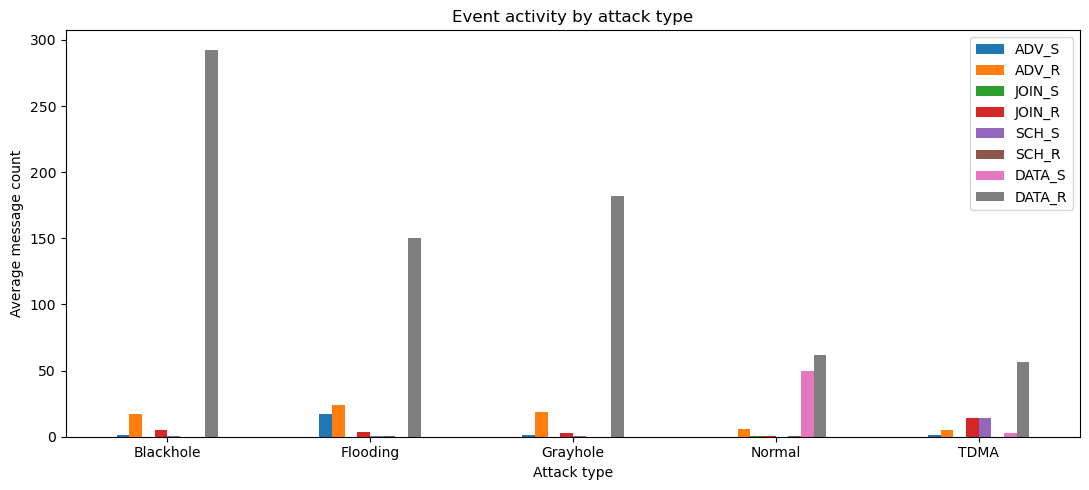

In [4]:
event_cols = ["ADV_S", "ADV_R", "JOIN_S", "JOIN_R", "SCH_S", "SCH_R", "DATA_S", "DATA_R"]
print("\nAverage event counts per attack type:")
print(df.groupby("Attack type")[event_cols].mean().round(2))

df.groupby("Attack type")[event_cols].mean().plot(kind="bar", figsize=(11, 5))
plt.title("Event activity by attack type")
plt.ylabel("Average message count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [6]:
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)


Accuracy: 0.9968
              precision    recall  f1-score   support

   Blackhole       0.99      0.99      0.99       545
    Flooding       0.93      0.97      0.95       178
    Grayhole       0.98      0.98      0.98       795
      Normal       1.00      1.00      1.00     18125
        TDMA       1.00      0.94      0.97       357

    accuracy                           1.00     20000
   macro avg       0.98      0.98      0.98     20000
weighted avg       1.00      1.00      1.00     20000



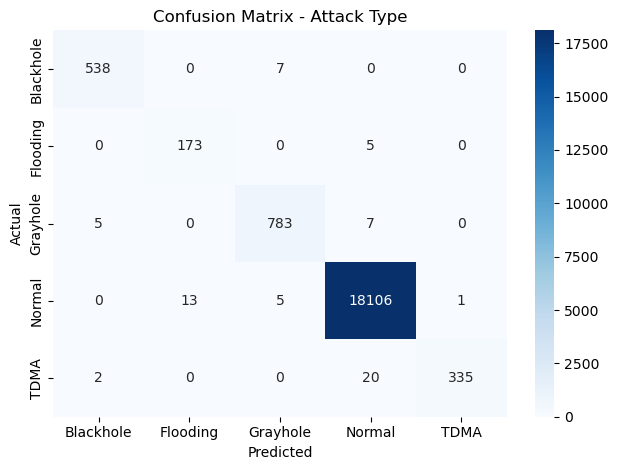

In [7]:
print("\nAccuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred))

labels = sorted(y.unique())
sns.heatmap(confusion_matrix(y_test, pred, labels=labels), annot=True, fmt="d",
            cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - Attack Type")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [8]:
actual_bin = (y_test != "Normal").map({False: "Normal", True: "Malicious"})
pred_bin = pd.Series(pred != "Normal", index=y_test.index).map({False: "Normal", True: "Malicious"})
print("\nMalicious vs Normal:")
print(classification_report(actual_bin, pred_bin))


Malicious vs Normal:
              precision    recall  f1-score   support

   Malicious       0.99      0.98      0.99      1875
      Normal       1.00      1.00      1.00     18125

    accuracy                           1.00     20000
   macro avg       0.99      0.99      0.99     20000
weighted avg       1.00      1.00      1.00     20000



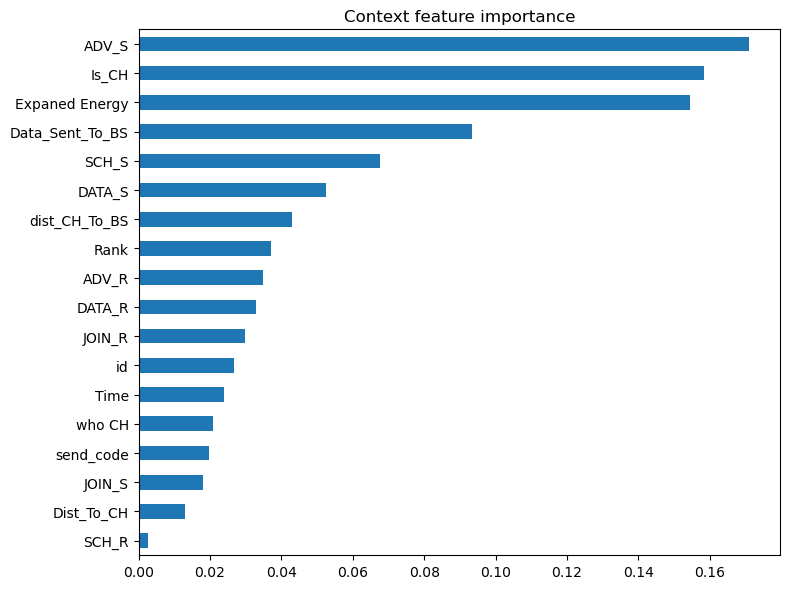

In [9]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 6), title="Context feature importance")
plt.tight_layout()
plt.show()

In [10]:
sample = X_test.head(5)
print("\nSample predictions:")
for (_, row), p, actual in zip(sample.iterrows(), model.predict(sample), y_test.head(5)):
    print(f"Node {row['id']}, Time {row['Time']}: predicted = {p}, actual = {actual}")


Sample predictions:
Node 107085.0, Time 353.0: predicted = Normal, actual = Normal
Node 109082.0, Time 453.0: predicted = Normal, actual = Normal
Node 903007.0, Time 3353.0: predicted = Grayhole, actual = Grayhole
Node 217061.0, Time 1853.0: predicted = Normal, actual = Normal
Node 106025.0, Time 303.0: predicted = Normal, actual = Normal
